### Specs:
- CPU: Intel Core Ultra 9 (x86-64)
- Numpy version: 2.5.4
- RAM: 16GB

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
print(np.__version__)

2.5.4


In [2]:

def my_psnr(ref, img):
    mse = np.mean((ref - img)**2)
    return 10 * np.log10(1.0 / mse) if mse > 0 else np.inf


def my_ssim(ref, img):
    w = 7
    a = sliding_window_view(ref, (w, w), axis=(0, 1))
    b = sliding_window_view(img, (w, w), axis=(0, 1))

    mu_a = a.mean(axis=(-2, -1))
    mu_b = b.mean(axis=(-2, -1))

    var_a = a.var(axis=(-2, -1), ddof=1)
    var_b = b.var(axis=(-2, -1), ddof=1)

    cov = ((a - mu_a[..., None, None]) *
           (b - mu_b[..., None, None])).sum(axis=(-2, -1)) / (w * w - 1)

    C1, C2 = 0.01**2, 0.03**2

    score = ((2 * mu_a * mu_b + C1) * (2 * cov + C2)) / (
        (mu_a**2 + mu_b**2 + C1) * (var_a + var_b + C2)
    )

    return score.mean()



### 5.1 Wiener Filter Derivation

For additive noise,

$$g=f+n \implies G=F+N$$

Let linear estimator $\hat F=WG$ minimizing

$$J(W)=E[|F-WG|^2]$$
= 
$$
J(W)=E[|F|^2]-WE[GF^*]-W^*E[FG^*]+|W|^2E[|G|^2]
$$

Differentiating with respect to $W^*$ and setting to zero,

$$
W=\frac{E[FG^*]}{E[|G|^2]}
$$

For uncorrelated, zero-mean, wide-sense stationary signal and noise,

$$
E[FG^*]=S_{ff},\qquad
E[|G|^2]=S_{ff}+S_{nn}
$$

Hence,

$$
\boxed{W(u,v)=\frac{S_{ff}(u,v)}{S_{ff}(u,v)+S_{nn}(u,v)}}
$$

and

$$
\boxed{\hat F(u,v)=W(u,v)G(u,v)}
$$


Image shape: (2048, 3072, 3)


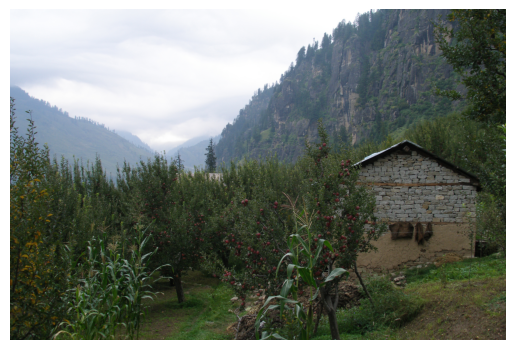

In [3]:
clean = np.asarray(Image.open(r"A2\Q5,6\reference_image.jpg").convert("RGB"),dtype=float) / 255.0
print("Image shape:", clean.shape)
plt.imshow(clean)
plt.axis("off")
plt.show()

In [4]:

from numpy.lib.stride_tricks import sliding_window_view

def uniform_filter_wrap(arr, size):
    pad = size // 2
    padded = np.pad(arr, pad, mode="wrap")
    windows = sliding_window_view(padded, (size, size))
    return windows.mean(axis=(-2, -1))

def wiener_denoise(img, sigma, smooth=15):
    out = np.empty_like(img)
    Sn = sigma**2

    for c in range(3):
        G = np.fft.fft2(img[:, :, c])
        Sg = uniform_filter_wrap(np.abs(G)**2 / G.size, smooth)
        Sf = np.maximum(Sg - Sn, 0)

        W = Sf / (Sf + Sn + 1e-12)
        out[:, :, c] = np.fft.ifft2(W * G).real

    return np.clip(out, 0, 1)



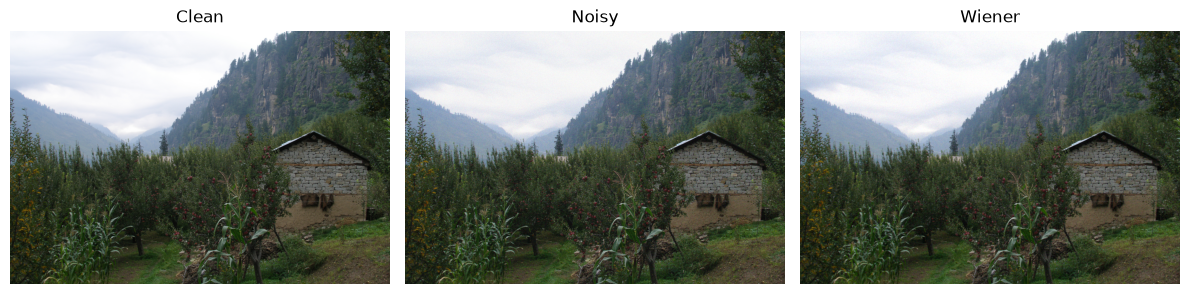

In [5]:
rng = np.random.default_rng(42)

sigma = 20 / 255
noisy = clean + rng.normal(0, sigma, clean.shape)
denoised = wiener_denoise(noisy, sigma)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, im, title in zip(
    axes, [clean, noisy, denoised],
    ["Clean", "Noisy", "Wiener"]
):
    ax.imshow(np.clip(im, 0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:
def make_filter(kind, P, D0, n=None, highpass=False):
    u = np.arange(P) - P // 2
    U, V = np.meshgrid(u, u)
    D = np.sqrt(U**2 + V**2)

    if kind == "ideal":
        H = (D <= D0).astype(float)
    elif kind == "butterworth":
        H = 1 / (1 + (D / D0)**(2*n))
    elif kind == "gaussian":
        H = np.exp(-D**2 / (2*D0**2))
    else:
        raise ValueError("Unknown filter type")

    return 1 - H if highpass else H

def lowpass_rgb(img, kind, D0, n=2):
    M, N, C = img.shape
    P = 2 * max(M, N)
    cutoff = D0 / np.sqrt(2*np.log(2)) if kind == "gaussian" else D0
    H = np.fft.ifftshift(make_filter(kind, P, cutoff, n))

    out = np.empty_like(img)
    for c in range(C):
        F = np.fft.fft2(img[:, :, c], s=(P, P))
        out[:, :, c] = np.fft.ifft2(F * H).real[:M, :N]

    return np.clip(out, 0, 1)

def bilateral_rgb(img, sigma_s, sigma_r, radius=3):
    M, N, _ = img.shape
    padded = np.pad(img, ((radius, radius), (radius, radius), (0, 0)), mode="reflect")
    result = np.zeros_like(img)
    norm = np.zeros((M, N))

    for dy in range(-radius, radius + 1):
        for dx in range(-radius, radius + 1):
            neighbor = padded[radius+dy:radius+dy+M, radius+dx:radius+dx+N]
            dist2 = np.mean((neighbor - img)**2, axis=2)
            w = np.exp(-(dx**2+dy**2)/(2*sigma_s**2) - dist2/(2*sigma_r**2))
            result += w[:, :, None] * neighbor
            norm += w

    return result / norm[:, :, None]



In [7]:

rng = np.random.default_rng(42)
noise_levels = [5, 10, 20, 40]
results = []

for level in noise_levels:
    sigma = level / 255
    noisy = clean + rng.normal(0, sigma, clean.shape)

    outputs = {
        "Noisy": np.clip(noisy, 0, 1),
        "Wiener": wiener_denoise(noisy, sigma),
        "Gaussian": lowpass_rgb(noisy, "gaussian", 2000),
        "Butterworth": lowpass_rgb(noisy, "butterworth", 2000, n=2),
        "Bilateral": np.clip(bilateral_rgb(noisy, 1.4, 2*sigma), 0, 1)
    }

    for name, out in outputs.items():
        psnr = my_psnr(clean, out)
        ssim = my_ssim(clean, out)
        results.append((level, name, psnr, ssim))


In [8]:
df = pd.DataFrame(results, columns=["Noise sigma", "Method", "PSNR", "SSIM"])
print("PSNR (dB)")
display(df.pivot(index="Noise sigma", columns="Method", values="PSNR").round(3))
print("SSIM")
display(df.pivot(index="Noise sigma", columns="Method", values="SSIM").round(4))

PSNR (dB)


Method,Bilateral,Butterworth,Gaussian,Noisy,Wiener
Noise sigma,,,,,
5,38.832,37.661,37.260,34.292,38.037
10,35.311,33.401,33.470,28.409,34.276
20,31.586,28.074,28.354,22.664,30.909
40,27.308,22.488,22.819,17.181,28.066


SSIM


Method,Bilateral,Butterworth,Gaussian,Noisy,Wiener
Noise sigma,,,,,
5,0.9537,0.9411,0.9408,0.8503,0.9400
10,0.9052,0.8380,0.8427,0.6292,0.8777
20,0.7982,0.6189,0.6285,0.3559,0.7844
40,0.5918,0.3484,0.3567,0.1569,0.6726


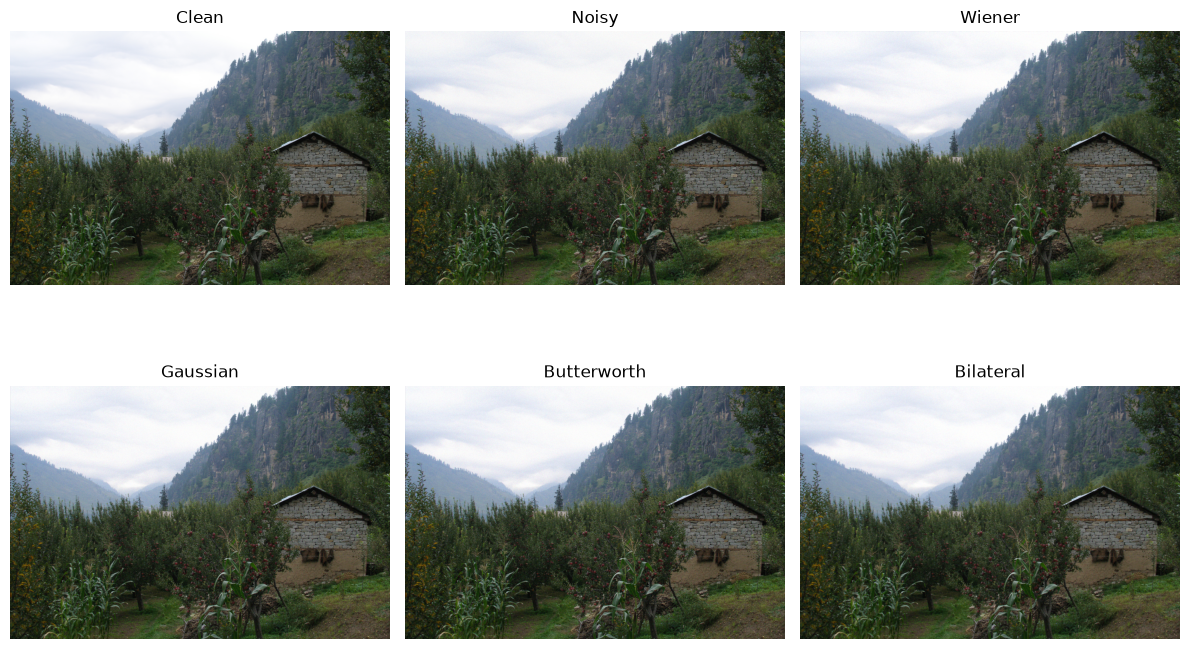

In [9]:
sigma = 15 / 255
rng = np.random.default_rng(42)
noisy = clean + rng.normal(0, sigma, clean.shape)

images = [
    clean,
    np.clip(noisy, 0, 1),
    wiener_denoise(noisy, sigma),
    lowpass_rgb(noisy, "gaussian", 2000),
    lowpass_rgb(noisy, "butterworth", 2000, n=2),
    np.clip(bilateral_rgb(noisy, 1.4, 2*sigma), 0, 1)
]

titles = ["Clean", "Noisy", "Wiener", "Gaussian", "Butterworth", "Bilateral"]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, im, title in zip(axes.flat, images, titles):
    ax.imshow(np.clip(im, 0, 1))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()



### 5.1 

Gaussian noise with $\sigma=\{5,10,20,40\}$ was added to the clean RGB reference image.

**Parameters:**
- Wiener: Signal PSD estimated using a $15\times15$ smoothed noisy-image periodogram after subtracting the known white-noise PSD.
- Gaussian: Matched half-amplitude radius $D_0=2000$.
- Butterworth: $D_0=2000$, order $n=2$.
- Bilateral: $7\times7$ window, $\sigma_s=1.4$, $\sigma_r=2\sigma_{\text{noise}}$.

**Wiener shrinkage:**

$$
W(u,v)=\frac{S_{ff}(u,v)}{S_{ff}(u,v)+S_{nn}(u,v)}
$$

Frequencies dominated by signal power receive gains close to 1, while noise-dominated frequencies are attenuated. Increasing noise power generally increases this attenuation.

Gaussian and Butterworth filters primarily suppress frequencies according to radial distance from the origin, regardless of their signal-to-noise ratio. Wiener filtering instead adapts to the estimated spectral signal and noise powers.

The Wiener filter minimizes mean-squared error among linear estimators under the stated second-order statistical assumptions when the true PSDs are known. With estimated PSDs, this optimality is approximate. It does not guarantee superior PSNR or SSIM against every nonlinear filter, such as bilateral filtering.

In [10]:
#updated
def wiener_denoise(img, sigma, smooth=15, noise_factor=1):
    out = np.empty_like(img)
    Sn = noise_factor * sigma**2

    for c in range(img.shape[2]):
        G = np.fft.fft2(img[:, :, c])
        Sg = uniform_filter_wrap(np.abs(G)**2 / G.size, smooth)
        Sf = np.maximum(Sg - Sn, 0)

        W = Sf / (Sf + Sn + 1e-12)
        out[:, :, c] = np.fft.ifft2(W * G).real

    return np.clip(out, 0, 1)


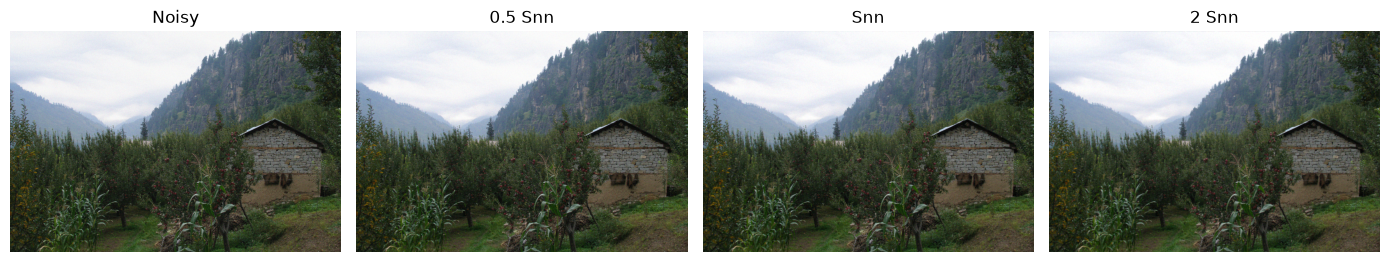

In [11]:
rng = np.random.default_rng(42)
sigma = 20 / 255

noisy = clean + rng.normal(0, sigma, clean.shape)

factors = [0.5, 1, 2]
outputs = [wiener_denoise(noisy, sigma, noise_factor=f) for f in factors]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, im, title in zip(
    axes,
    [np.clip(noisy, 0, 1)] + outputs,
    ["Noisy", "0.5 Snn", "Snn", "2 Snn"]
):
    ax.imshow(np.clip(im, 0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

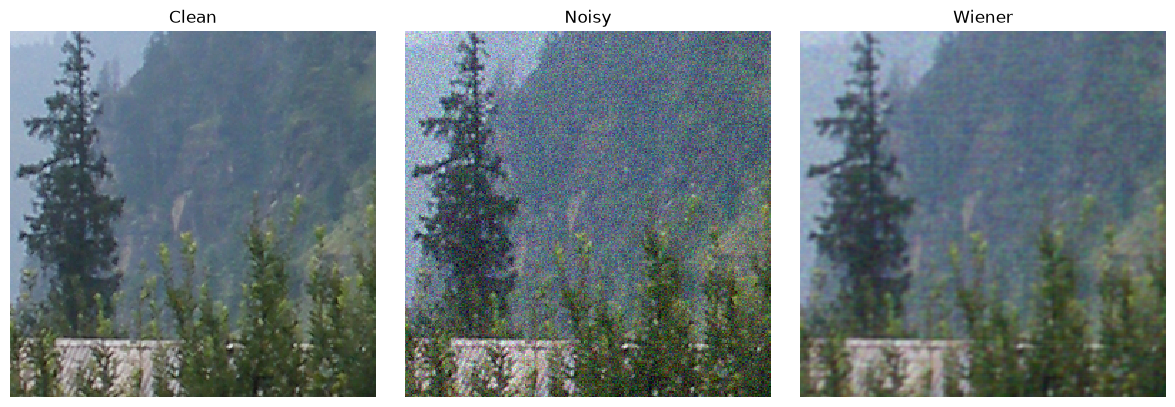

In [12]:
def show_crops(images, titles, r0=800, c0=1200, size=256, resid_ref=None):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 4))
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(np.clip(im[r0:r0+size, c0:c0+size], 0, 1), interpolation="nearest")
        ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.show()

sigma = 20 / 255
rng = np.random.default_rng(42)
noisy = clean + rng.normal(0, sigma, clean.shape)
denoised = wiener_denoise(noisy, sigma)

show_crops(
    [clean, noisy, denoised],
    ["Clean", "Noisy", "Wiener"]
)

In [13]:
print(f"{'Assumed Noise Power':<22} {'PSNR (dB)':>12} {'SSIM':>10}")
for f, out in zip(factors, outputs):
    psnr = my_psnr(clean, out)
    ssim = my_ssim(clean, out)
    print(f"{f:<22} {psnr:>12.3f} {ssim:>10.4f}")

Assumed Noise Power       PSNR (dB)       SSIM
0.5                          26.969     0.5501
1                            30.911     0.7847
2                            29.580     0.7804



### 5.2(a) Noise-Power Mis-estimation
- Underestimating noise power produces weaker attenuation, retaining more noise and fine detail.
- Correct noise power provides the appropriate shrinkage under the estimated spectral model.
- Overestimating noise power produces stronger attenuation, potentially removing noise at the cost of blurring useful details.

Note: implementation uses the assumed noise power for both noise subtraction and Wiener gain calculation. Therefore, underestimating noise power affects not just the denominator, but also increases the estimated signal PSD. This compounds the under-smoothing effect



### 5.2(b) Edge Blurring

Even with correctly specified noise power, Wiener filtering may blur edges because edges contain high-frequency components that can be attenuated along with noise.
The Wiener filter minimizes expected MSE among linear estimators under the assumed second-order statistical model, but does not explicitly prioritize edge preservation.
Furthermore, real images are spatially non-stationary: smooth regions, textures, and boundaries have different local statistics. A global PSD estimate cannot fully represent these variations.

Thus, MMSE optimality does not guarantee sharp edges or the best perceptual quality.


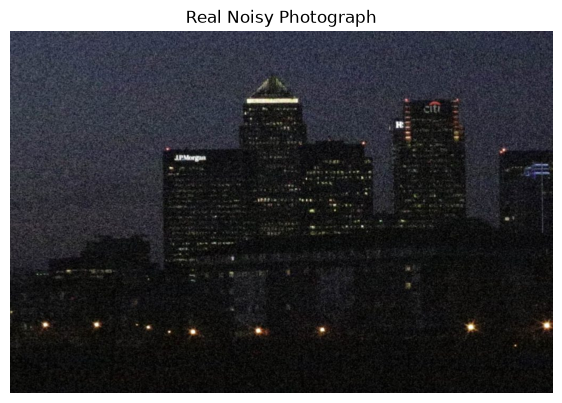

In [14]:
real = np.asarray(Image.open("noisy_photo.jpeg").convert("RGB"), dtype=float) / 255.0
plt.figure(figsize=(7, 5))
plt.imshow(real)
plt.title("Real Noisy Photograph")
plt.axis("off")
plt.show()

In [15]:
def estimate_sigma(img):
    h, w = img.shape[:2]; img = img[:h//2*2, :w//2*2]
    s = []
    for c in range(img.shape[2]):
        x = img[..., c]
        hh = (x[0::2,0::2] - x[0::2,1::2] - x[1::2,0::2] + x[1::2,1::2]) / 2
        s.append(np.median(np.abs(hh)) / 0.6745)
    return float(np.mean(s))

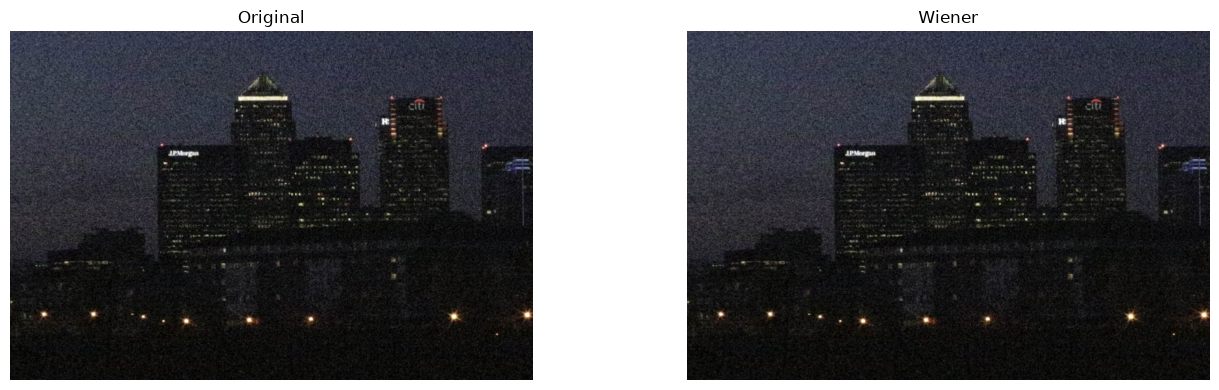

In [16]:
real_denoised = wiener_denoise(real, estimate_sigma(real))
residual = real - real_denoised
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(real)
axes[0].set_title("Original")
axes[1].imshow(real_denoised)
axes[1].set_title("Wiener")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


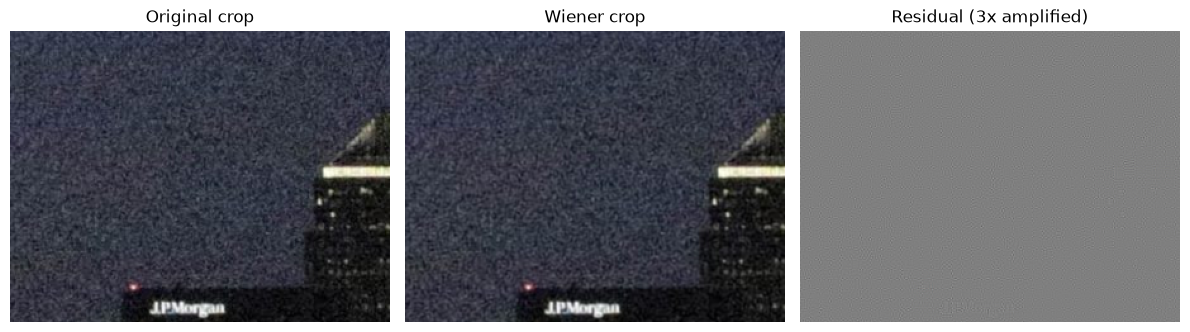

In [17]:

r0, r1, c0, c1 = 20, 250, 200, 500

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(real[r0:r1, c0:c1])
ax[0].set_title("Original crop")

ax[1].imshow(np.clip(real_denoised[r0:r1, c0:c1], 0, 1))
ax[1].set_title("Wiener crop")

res = residual[r0:r1, c0:c1]
ax[2].imshow(np.clip(0.5 + 3*res, 0, 1))
ax[2].set_title("Residual (3x amplified)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


### 5.2(c) Real-Noise Experiment
Compared with the synthetic case, the Wiener filter changed this photo very little. In the synthetic images there was a lot of smoothening (As visible in the zoomed, cropped photos) but we dont see much smoothening in the real case as for real photos, noise is not white. Real photographic noise may be signal-dependent and spatially correlated, so a single constant noise PSD may not accurately represent its frequency-dependent or spatially varying characteristics. Consequently, Wiener filtering based on this approximation may leave residual noise or remove genuine image detail.

**Limitations of the white-noise assumption:**
- **Signal-dependent noise:** Sensor noise may depend on image intensity, particularly in darker regions.
- **Spatially correlated noise:** Demosaicing and sharpening can introduce correlations between neighboring pixels.
- **Channel correlation:** Demosaicing and color processing can correlate noise across RGB channels.
- **Compression:** JPEG compression can introduce blocking and structured artifacts that are not white Gaussian noise.

Real photographic noise may be signal-dependent, spatially correlated, and affected by demosaicing, sharpening, and JPEG compression. Consequently, a single flat noise PSD may not accurately represent the noise in every region or frequency band.
Since no clean registered reference is available, the comparison is qualitative and PSNR/SSIM are not reported.